** Keras DNN (은닉층 여러 개) - EuroSAT 이미지 분류

ANN과 동일한 파이프라인이지만, Dense 은닉층을 3개로 깊게 쌓은 버전입니다.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os, shutil

SPLIT_DIR = '/content/eurosat_split'
DRIVE_ZIP = '/content/drive/MyDrive/eurosat_split.zip'

if not os.path.exists(SPLIT_DIR) and os.path.exists(DRIVE_ZIP):
    shutil.unpack_archive(DRIVE_ZIP, SPLIT_DIR)
    print('Drive에서 압축 해제 완료')
else:
    print('SPLIT_DIR:', SPLIT_DIR)

Mounted at /content/drive
Drive에서 압축 해제 완료


In [ ]:
import tensorflow as tf

print('GPU 사용 가능:', tf.config.list_physical_devices('GPU'))

IMG_SIZE = (64, 64)
BATCH_SIZE = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(SPLIT_DIR, 'train'), image_size=IMG_SIZE, batch_size=BATCH_SIZE, seed=42)
val_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(SPLIT_DIR, 'val'), image_size=IMG_SIZE, batch_size=BATCH_SIZE, seed=42)
test_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(SPLIT_DIR, 'test'), image_size=IMG_SIZE, batch_size=BATCH_SIZE, seed=42)

class_names = train_ds.class_names
num_classes = len(class_names)
print('클래스 수:', num_classes)

GPU 사용 가능: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Found 18900 files belonging to 10 classes.
Found 4050 files belonging to 10 classes.
Found 4050 files belonging to 10 classes.
클래스 수: 10


In [ ]:
normalization_layer = tf.keras.layers.Rescaling(1./255)
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.map(lambda x, y: (normalization_layer(x), y)).cache().prefetch(AUTOTUNE)
val_ds = val_ds.map(lambda x, y: (normalization_layer(x), y)).cache().prefetch(AUTOTUNE)
test_ds = test_ds.map(lambda x, y: (normalization_layer(x), y)).cache().prefetch(AUTOTUNE)

## DNN 모델 정의
은닉층 3개(512-256-128)를 쌓은 깊은 완전연결 신경망입니다.

In [ ]:
def build_dnn(input_shape, num_classes):
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=input_shape),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(512, activation='relu'),
        tf.keras.layers.Dropout(0.3),
        tf.keras.layers.Dense(256, activation='relu'),
        tf.keras.layers.Dropout(0.3),
        tf.keras.layers.Dense(128, activation='relu'),
        tf.keras.layers.Dropout(0.3),
        tf.keras.layers.Dense(num_classes, activation='softmax'),
    ])
    return model

model = build_dnn((64, 64, 3), num_classes)
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 12288)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     6,291,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,457,482 (24.63 MB)

 Trainable params: 6,457,482 (24.63 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy'],
)

callbacks = [
    tf.keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=3),
]

In [ ]:
import time

start_time = time.time()
history = model.fit(train_ds, validation_data=val_ds, epochs=50, callbacks=callbacks)
training_time = time.time() - start_time
print(f'학습 시간: {training_time:.1f}초')

Epoch 1/50
591/591 ━━━━━━━━━━━━━━━━━━━━ 15s 17ms/step - accuracy: 0.1941 - loss: 2.1184 - val_accuracy: 0.3156 - val_loss: 1.8396 - learning_rate: 0.0010
Epoch 2/50
591/591 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.2344 - loss: 1.9595 - val_accuracy: 0.3000 - val_loss: 1.8492 - learning_rate: 0.0010
Epoch 3/50
591/591 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.2674 - loss: 1.9031 - val_accuracy: 0.3533 - val_loss: 1.7709 - learning_rate: 0.0010
Epoch 4/50
591/591 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.2813 - loss: 1.8645 - val_accuracy: 0.3733 - val_loss: 1.7106 - learning_rate: 0.0010
Epoch 5/50
591/591 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.2882 - loss: 1.8447 - val_accuracy: 0.3657 - val_loss: 1.6915 - learning_rate: 0.0010
Epoch 6/50
591/591 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.2970 - loss: 1.8337 - val_accuracy: 0.3760 - val_loss: 1.6643 - learning_rate: 0.0010
Epoch 7/50
591/591 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.3021 - loss: 1.8218 

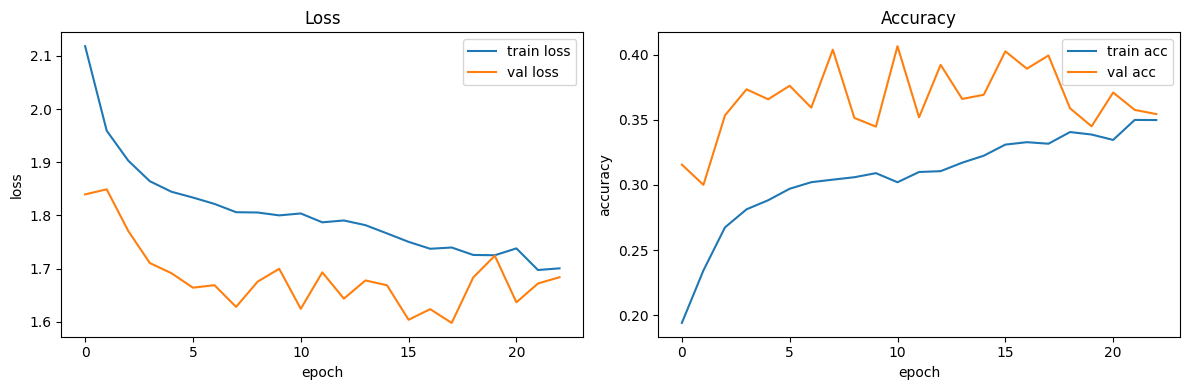

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history.history['loss'], label='train loss')
axes[0].plot(history.history['val_loss'], label='val loss')
axes[0].set_xlabel('epoch'); axes[0].set_ylabel('loss'); axes[0].legend(); axes[0].set_title('Loss')
axes[1].plot(history.history['accuracy'], label='train acc')
axes[1].plot(history.history['val_accuracy'], label='val acc')
axes[1].set_xlabel('epoch'); axes[1].set_ylabel('accuracy'); axes[1].legend(); axes[1].set_title('Accuracy')
plt.tight_layout(); plt.show()

In [ ]:
test_loss, test_acc = model.evaluate(test_ds)
num_params = model.count_params()
print(f'Test accuracy: {test_acc:.4f}')
print(f'Test loss: {test_loss:.4f}')
print(f'파라미터 수: {num_params:,}')

127/127 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.3909 - loss: 1.6003
Test accuracy: 0.3909
Test loss: 1.6003
파라미터 수: 6,457,482


In [ ]:
import pandas as pd

RESULTS_PATH = '/content/drive/MyDrive/model_results.csv'
row = {
    'model': 'DNN', 'framework': 'Keras',
    'test_accuracy': test_acc, 'test_loss': test_loss,
    'num_params': num_params, 'training_time_sec': training_time,
    'epochs_ran': len(history.history['loss']),
}

if os.path.exists(RESULTS_PATH):
    results_df = pd.read_csv(RESULTS_PATH)
    results_df = results_df[~((results_df['model'] == row['model']) & (results_df['framework'] == row['framework']))]
    results_df = pd.concat([results_df, pd.DataFrame([row])], ignore_index=True)
else:
    results_df = pd.DataFrame([row])

results_df.to_csv(RESULTS_PATH, index=False)
results_df

,model,framework,test_accuracy,test_loss,num_params,training_time_sec,epochs_ran
0,ANN,PyTorch,0.446420,1.503735,3148554,178.828007,16
1,DNN,PyTorch,0.430864,1.526692,6457482,215.528363,17
2,CNN,Keras,0.873086,0.429663,2194122,81.434472,14
3,CNN,PyTorch,0.947407,0.190860,2193674,513.813921,34
4,ANN,Keras,0.273827,1.791635,3148554,65.389723,28
5,DNN,Keras,0.390864,1.600345,6457482,71.961101,23
